<a href="https://colab.research.google.com/github/morenomarisa/AnonimizadorRegex/blob/main/token_count.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [15]:
import pandas as pd
import numpy as np
import re
import statistics
import matplotlib.pyplot as plt

In [16]:
df_trezentos = pd.read_excel(r"/content/drive/MyDrive/ProjetosCod/Anonimizador_Regex/Analise-Anonimizador-master/BOS.xlsx")

In [17]:
df_gabarito = pd.read_excel(r"/content/drive/MyDrive/ProjetosCod/Anonimizador_Regex/Analise-Anonimizador-master/trezentinhos-GABARITO-Valor Monetario sem virgula e simbolo.xlsx")

In [18]:
def tokenize(text):
    RE_TOKEN = re.compile(
        r"""([#]?[@\w'’\+\-.,]*[\w][$]?|[:;<]\-?[\)\(3])""", re.VERBOSE)
    return RE_TOKEN.findall(text)

In [19]:
def count_tokens_number(df, name_column):
    count_list = []

    for relato in df[name_column]:
        count = 0
        if pd.notnull(relato):
            tokenized_relato = tokenize(str(relato))
            for token in tokenized_relato:
                #print(token)
                count += 1
            count_list.append(count)
    return count_list

def count_tokens_symbol(df, name_column):
    tokens_list = []
    for relato in df[name_column]:
        tokenized_relato = tokenize(str(relato))
        for token in tokenized_relato:
            #print(token)
            tokens_list.append(token)
    #print(tokens_list)
    return tokens_list

In [20]:
count = count_tokens_number(df_trezentos, 'relato')
count_tokens = count_tokens_symbol(df_trezentos, 'relato')
#print(count_tokens)

print(f"Tamanho lista de contagem (Qtd BOS): {len(count)}")
print(f"Maior quantidade de tokens em um BO: {max(count)}")
print(f"Menor quantidade de tokens em um BO: {min(count)}")
print(f"Quantidade total de tokens na BD: {len(count_tokens)}")
#print(f"Quantidade total de tokens na BD: {sum(count)}")
print(f"Quantidade total de tokens únicos na BD: {len(set(count_tokens))}")
print(f"Quantidade média de tokens na BD: {statistics.fmean(count)}")
print(f"Desvio padrão de tokens da BD: {statistics.pstdev(count)}")
print(f"Desvio padrão de tokens da BD: {np.std(count)}")

Tamanho lista de contagem (Qtd BOS): 300
Maior quantidade de tokens em um BO: 1696
Menor quantidade de tokens em um BO: 32
Quantidade total de tokens na BD: 62765
Quantidade total de tokens únicos na BD: 7626
Quantidade média de tokens na BD: 209.21666666666667
Desvio padrão de tokens da BD: 177.4995109539429
Desvio padrão de tokens da BD: 177.4995109539429


In [21]:
print(set(count_tokens))

{'CEPEX', 'HONORARIOS', 'DEZOITO', 'PERFIL', 'PLATAFORMA', 'QUINZE', 'DIGITAL', 'PASSADOR', 'CONSIGNACAO', 'FUNDEB', '159.90', 'TER', 'MEDIO', 'SILVA', 'SAIDA', 'GENITOR', 'CIO', 'A782EF7C-526A-48D2-8A42-F9D42D5134F4', '0743', 'JUNIOR', 'AVISARAM', 'FICHA', 'CRIANCAS', 'PIMHO', '2869', 'ENVIAM', 'ORGAO', 'INTENSO', 'APRESENTANDO', '00', 'HTTP', '2006887-6', 'DI', 'WPP', '11', 'SOLUCOES', 'CAMPOS', 'MACHUQUEI', 'ESTE', 'MARTA', 'MOOZ', 'SIMULOU', '98905-6466', 'SENSITIVA', 'CESAR', 'BRASIL', 'VIVIAN', '+39', 'DESCRITAS', 'HACKEAR', 'PROCURANDO', 'RAPIDA,ONDE', 'VELHA', 'SEGUNDA-FEIRA', 'PERCEBEU', 'CUIDADO', 'CONSIGNADOS', 'PENHA', '98027-0161', 'DATA', '.644.347', 'PERSEGUIDO', 'EQUIPAMENTOS', 'APAGAMENTO', '4.900.00', '98425-3954', 'BATENDO', 'RODRIGUES', 'MIRANTE', 'PESSOAS', '97961-3969', 'AGUDOU', 'CHEGO', 'DUAS', 'REGISTROU', '3BCF', '00032530-8', '9161-3281', '487.045.078-00', 'DIVINA', 'DIFAMATORIOS', 'DEVIDAMENTE', 'TIPO', 'PERDERA', '13.696803', 'SEGURANDO', 'CONVERSAR', 'MARI

In [22]:
print(f"NOMES: {sum(count_tokens_number(df_trezentos, 'NOMES'))}")
print(f"TELEFONE: {sum(count_tokens_number(df_trezentos, 'TELEFONE'))}")
print(f"CPF/CNPJ: {sum(count_tokens_number(df_trezentos, 'CPF/CNPJ'))}")
print(f"EMAIL: {sum(count_tokens_number(df_trezentos, 'EMAIL'))}")
print(f"AGENCIA E CONTA: {sum(count_tokens_number(df_trezentos, 'AGENCIA E CONTA'))}")



NOMES: 1928
TELEFONE: 609
CPF/CNPJ: 283
EMAIL: 49
AGENCIA E CONTA: 626


In [23]:
print(f"NOMES: {sum(count_tokens_number(df_gabarito, 'NOMES'))}")
print(f"TELEFONE: {sum(count_tokens_number(df_gabarito, 'TELEFONE'))}")
print(f"CPF/CNPJ: {sum(count_tokens_number(df_gabarito, 'CPF/CNPJ'))}")
print(f"EMAIL: {sum(count_tokens_number(df_gabarito, 'EMAIL'))}")
print(f"AGENCIA E CONTA: {sum(count_tokens_number(df_gabarito, 'AGENCIA E CONTA'))}")



NOMES: 1617
TELEFONE: 728
CPF/CNPJ: 177
EMAIL: 40
AGENCIA E CONTA: 637


In [24]:
count_unique = count_tokens_symbol(df_trezentos, 'relato')
len((count_unique))

62765

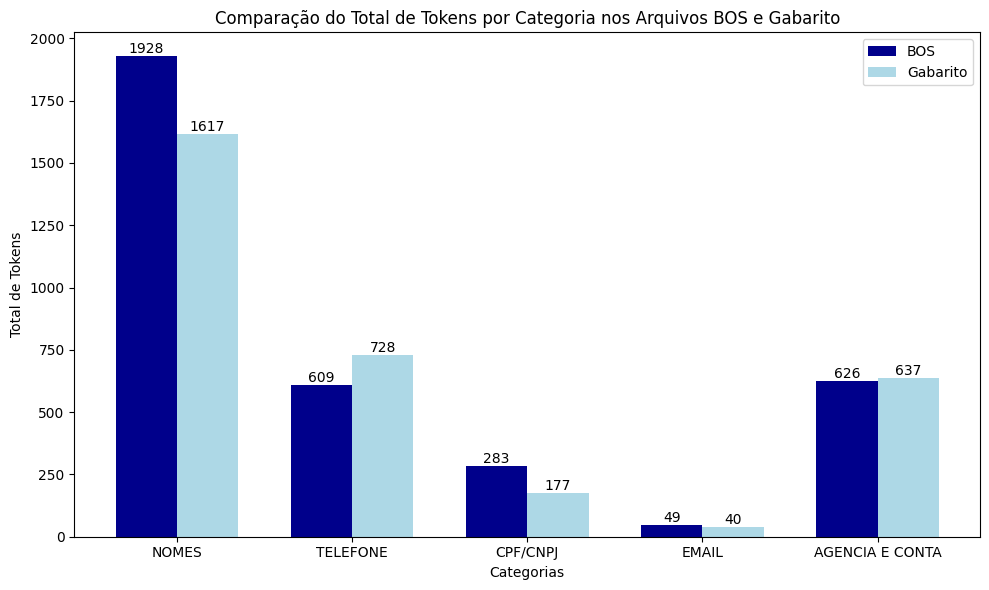

In [46]:
categories = ["NOMES", "TELEFONE", "CPF/CNPJ", "EMAIL", "AGENCIA E CONTA"]

# Contagem de tokens nos arquivos BOS
bos_counts = [
    sum(count_tokens_number(df_trezentos, 'NOMES')),
    sum(count_tokens_number(df_trezentos, 'TELEFONE')),
    sum(count_tokens_number(df_trezentos, 'CPF/CNPJ')),
    sum(count_tokens_number(df_trezentos, 'EMAIL')),
    sum(count_tokens_number(df_trezentos, 'AGENCIA E CONTA'))
]

# Contagem de tokens nos arquivos Gabarito
gabarito_counts = [
    sum(count_tokens_number(df_gabarito, 'NOMES')),
    sum(count_tokens_number(df_gabarito, 'TELEFONE')),
    sum(count_tokens_number(df_gabarito, 'CPF/CNPJ')),
    sum(count_tokens_number(df_gabarito, 'EMAIL')),
    sum(count_tokens_number(df_gabarito, 'AGENCIA E CONTA'))
]

# Configurações para o gráfico de barras
bar_width = 0.35  # Largura das barras
index = range(len(categories))  # Índices das categorias

# Criação do gráfico de barras
plt.figure(figsize=(10, 6))

# Barras para BOS
plt.bar(index, bos_counts, bar_width, color='darkblue', label='BOS')

# Barras para Gabarito
plt.bar([i + bar_width for i in index], gabarito_counts, bar_width, color='lightblue', label='Gabarito')

# Adicionando rótulos às barras
for bar in bars_bos:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2.0,
        height,
        f'{height}',
        ha='center',
        va='bottom'
    )

for bar in bars_gabarito:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2.0,
        height,
        f'{height}',
        ha='center',
        va='bottom'
    )

# Configurações de título e eixos
plt.xlabel('Categorias')
plt.ylabel('Total de Tokens')
plt.title('Comparação do Total de Tokens por Categoria nos Arquivos BOS e Gabarito')
plt.xticks([i + bar_width / 2 for i in index], categories)  # Ajuste da posição das labels no eixo X
plt.legend()

# Exibir o gráfico
plt.tight_layout()
plt.show()